## Ejemplo 3: Early Stopping, Batch Normalization y Dropout

In [13]:
from tensorflow import keras
from tensorflow.keras import layers, callbacks

import pandas as pd

### Datos y preprocesamiento

In [9]:
# Usar la ruta correcta al archivo
df = pd.read_csv('/content/red-wine.csv')

# Conjunto de entrenamiento y validación
df_train = df.sample(frac=0.7, random_state=0)   # Entrenamiento
df_valid = df.drop(df_train.index)               # Validación

df_train.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1109,10.8,0.470,0.43,2.10,0.171,27.0,66.0,0.99820,3.17,0.76,10.8,6
1032,8.1,0.820,0.00,4.10,0.095,5.0,14.0,0.99854,3.36,0.53,9.6,5
1002,9.1,0.290,0.33,2.05,0.063,13.0,27.0,0.99516,3.26,0.84,11.7,7
487,10.2,0.645,0.36,1.80,0.053,5.0,14.0,0.99820,3.17,0.42,10.0,6
979,12.2,0.450,0.49,1.40,0.075,3.0,6.0,0.99690,3.13,0.63,10.4,5


In [10]:
# Escalar los atributos entre 0 y 1
vmax = df_train.max(axis=0)
vmin = df_train.min(axis=0)
df_train = (df_train - vmin) / (vmax - vmin)
df_valid = (df_valid - vmin) / (vmax - vmin)

df_train.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1109,0.548673,0.239726,0.544304,0.092308,0.237435,0.366197,0.212014,0.619193,0.291262,0.260606,0.369231,0.6
1032,0.309735,0.479452,0.000000,0.246154,0.105719,0.056338,0.028269,0.645088,0.475728,0.121212,0.184615,0.4
1002,0.398230,0.116438,0.417722,0.088462,0.050260,0.169014,0.074205,0.387662,0.378641,0.309091,0.507692,0.8
487,0.495575,0.359589,0.455696,0.069231,0.032929,0.056338,0.028269,0.619193,0.291262,0.054545,0.246154,0.6
979,0.672566,0.226027,0.620253,0.038462,0.071057,0.028169,0.000000,0.520183,0.252427,0.181818,0.307692,0.4


In [12]:
# Separar atributos y columna objetivo: se desea predecir la calidad
X_train = df_train.drop('quality', axis=1)
X_valid = df_valid.drop('quality', axis=1)

y_train = df_train['quality']
y_valid = df_valid['quality']

X_train.shape

(1119, 11)

### Red Neuronal usando "Early-Stopping"

In [14]:
# Callback para Early-Stopping
early_stopping = callbacks.EarlyStopping(
    min_delta=0.001,       # Mínimo cambio considerado "mejora"
    patience=20,           # Número de épocas antes de poder detener
    restore_best_weights=True,
)

In [22]:
model = keras.Sequential([
    layers.Dense(512, activation='relu', input_shape=[11]),
    layers.Dense(512, activation='relu'),
    layers.Dense(512, activation='relu'),
    layers.Dense(1),
])

model.compile(
    optimizer='adam',
    loss='mae',
)

In [23]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=500,
    callbacks=[early_stopping],        # llamada a la función de callback
    verbose=0,
)

Mínimo costo en validación: 0.09028654545545578


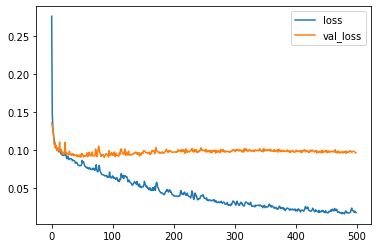

In [26]:
# Gráfico de los resultados
hdf = pd.DataFrame(history.history)

hdf.loc[0:, ['loss', 'val_loss']].plot()
print("Mínimo costo en validación: {}".format(hdf['val_loss'].min()))

### Red Neuronal usando Batch Normalization y Dropout

*Batch normalization*: 
* Permite normalizar dentro de la red neuronal
* En Keras se implementa como una capa especial: toma la capa de entrada, normaliza el batch con su media y desviación estándar, y luego genera una nueva escala con 2 parámetros de rescalamiento entrenables 
* En Keras se puede poner al final de una capa, o entre la capa y la activación
* Puede ayudar cuando el entrenamiento es lento o inestable debido a la optimización 
* Usualmente cuando hay batch normalization se requiere menos "epochs" de entrenamiento

```
   layers.Dense(32, activation='relu'),
   layers.BatchNormalization(),
```

*Dropout*:
* Aleatoriamente remueve algunas neuronas de cada capa 
* En Keras se define como una capa y se coloca antes de la capa a la cual se quiere aplicar dropout
* Cuando hay dropout usualmente las capas tienen más neuronas



```
   layers.Dropout(rate=0.4), # 40 % de dropout a la siguiente capa
   layers.Dense(32),
```



In [27]:
model = keras.Sequential([
    # Capa de entrada
    layers.Dense(1024, activation='relu', input_shape=[11]),
    # Capa 1
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(1024, activation='relu'),
    # Capa 2
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(1024, activation='relu'),
    # Capa 3
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(1),
])

In [28]:
model.compile(optimizer='adam', loss='mae')

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=100,
    verbose=0,
)

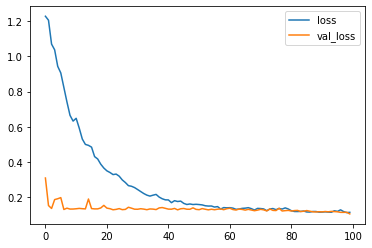

In [29]:
# Gráfico del costo
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot();